# Lab L3-4：AE 熱圖太模糊？用擴散模型「修好」板子再比對（D3-4）

**需求單 #D3-4**（虛構公司：曜嶼電子，製造品保部 A 線）：D2-1 的 AE 重建太模糊，細紋路一直被判成瑕疵（過殺）。
想法：把板子**加噪到第 t 步**（不是加到純雜訊），再用擴散模型去噪回來 → 得到「這片板子的正常版」。原圖和正常版相減，就是瑕疵。

| 步驟 | 做什麼 | 輸出 |
|---|---|---|
| 1 | 資料：VisA PCB1，和 D2-1 **同一個切分**；64 × 64 | 張數 |
| 2 | 對照組：D2-1 的卷積 AE（重新訓練，64 × 64） | 驗證集 AUROC |
| 3 | 擴散模型：講師在 PCB1 良品上訓練好的 DDPM（或自己訓練） | 檢查點 |
| 4 | 加噪到第 t 步、再去噪：t 掃一輪 | `t_sweep.png`、各 t 的 AUROC |
| 5 | DDIM：少走幾步，量每張幾毫秒 | 步數 vs AUROC vs 毫秒 |
| 6 | 測試集：AE vs 擴散，AUROC、過殺、漏檢、每秒幾張 | 對照表、`repair_examples.png` |

> 執行階段請選 **T4 GPU**。所有圖和數字最後會存進 `lab12_outputs.zip`。

In [1]:
# 第 1 格：環境
%pip install -q -U scikit-learn
import torch, os, glob, math, time, json, random, platform
import numpy as np
import matplotlib.pyplot as plt
print("torch", torch.__version__, "| python", platform.python_version())
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    free, total = torch.cuda.mem_get_info()
    print("GPU:", torch.cuda.get_device_name(0), f"| 可用 VRAM {free/1e9:.1f} / {total/1e9:.1f} GB")
SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
SIZE = 64
EPOCHS_AE = 30       # 沒有 GPU：改成 3
TRAIN_DDPM = False   # False：下載講師的檢查點（建議）；True：自己訓練（T4 約數分鐘，時間待實測）
STEPS_DDPM = 10000   # 自己訓練時的步數；沒有 GPU：改成 200
EVAL_N = None        # None＝全部；沒有 GPU：改成 20（每一類只取 20 張，數字不準，只為了跑得完）
TAKT_S = 1.0         # 產線節拍時間：每片板子幾秒（虛構的假設，請換成你們產線的數字）
RESULTS = {}

torch 2.14.1+cu130 | python 3.13.16
GPU: Tesla T4 | 可用 VRAM 15.5 / 15.6 GB


## 1. 資料：VisA PCB1，和 D2-1 同一個切分
和 D2-1 一樣下載 VisA（約 1.9 GB），只解壓 `pcb1`。用同一個 SEED、同一個切法 → 和 D2-1 的訓練／驗證／測試是同一批板子。

In [2]:
VISA_URL = "https://amazon-visual-anomaly.s3.us-west-2.amazonaws.com/VisA_20220922.tar"
CATEGORY = "pcb1"
DATA_DIR = f"visa/{CATEGORY}"   # 講師若放在雲端硬碟，改成那個資料夾

if not os.path.isdir(DATA_DIR):
    os.makedirs("visa", exist_ok=True)
    if not os.path.exists("visa/VisA.tar"):
        os.system(f"wget -q -O visa/VisA.tar {VISA_URL}")
    os.system(f"tar -xf visa/VisA.tar -C visa --wildcards '{CATEGORY}/*'")
normal = sorted(glob.glob(f"{DATA_DIR}/**/Normal/*.*", recursive=True))
anomaly = sorted(p for p in glob.glob(f"{DATA_DIR}/**/Anomaly/*.*", recursive=True) if "/Masks/" not in p.replace("\\", "/"))
random.shuffle(normal); random.shuffle(anomaly)                    # 和 D2-1 同樣的順序
n70, n85, a50 = int(len(normal) * 0.70), int(len(normal) * 0.85), len(anomaly) // 2
split = {"train": (normal[:n70], []), "val": (normal[n70:n85], anomaly[:a50]), "test": (normal[n85:], anomaly[a50:])}
for k, (g, b) in split.items():
    print(f"{k:5s} 良品 {len(g):4d}  不良 {len(b):3d}")

train 良品  702  不良   0
val   良品  151  不良  50
test  良品  151  不良  50


In [3]:
from PIL import Image
from torchvision.transforms.functional import to_tensor

def load(paths):
    return torch.stack([to_tensor(Image.open(p).convert("RGB").resize((SIZE, SIZE), Image.BILINEAR)) for p in paths]) if paths else torch.empty(0, 3, SIZE, SIZE)

def mask_path(p):
    p = p.replace("\\", "/")
    return os.path.splitext(p.replace("/Images/Anomaly/", "/Masks/Anomaly/"))[0] + ".png"

t0 = time.time()
X_train = load(split["train"][0])
X_train = torch.cat([X_train, X_train.flip(-2, -1)])               # 加 180° 旋轉（D2-1 的資料陷阱）
data = {}
for k in ("val", "test"):
    g, b = split[k]
    if EVAL_N: g, b = g[:EVAL_N], b[:EVAL_N]
    data[k] = dict(x=torch.cat([load(g), load(b)]), y=torch.tensor([0] * len(g) + [1] * len(b)),
                   m=torch.stack([torch.zeros(SIZE, SIZE)] * len(g) + [to_tensor(Image.open(mask_path(p)).convert("L").resize((SIZE, SIZE), Image.NEAREST))[0] for p in b]) > 0)
print(f"讀取完成 {time.time()-t0:.0f}s | 訓練 {len(X_train)} 張（含旋轉）| 一張", tuple(X_train[0].shape))

讀取完成 23s | 訓練 1404 張（含旋轉）| 一張 (3, 64, 64)


## 2. 對照組：D2-1 的卷積自編碼器（64 × 64 重新訓練）
分數和 D2-1 一樣：**誤差圖**（每個像素的平方誤差，三個通道平均）→ 誤差最大 1% 像素的平均。

In [4]:
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score

def down(cin, cout): return nn.Sequential(nn.Conv2d(cin, cout, 4, 2, 1), nn.BatchNorm2d(cout), nn.LeakyReLU(0.2))
def up(cin, cout): return nn.Sequential(nn.ConvTranspose2d(cin, cout, 4, 2, 1), nn.BatchNorm2d(cout), nn.ReLU())
ae = nn.Sequential(down(3, 32), down(32, 64), down(64, 128), down(128, 128),
                   up(128, 128), up(128, 64), up(64, 32), nn.ConvTranspose2d(32, 3, 4, 2, 1), nn.Sigmoid()).to(device)
opt = torch.optim.Adam(ae.parameters(), lr=1e-3)
t0 = time.time()
for epoch in range(1, EPOCHS_AE + 1):
    ae.train()
    for i in torch.randperm(len(X_train)).split(32):
        xb = X_train[i].to(device)
        loss = F.mse_loss(ae(xb), xb)
        opt.zero_grad(); loss.backward(); opt.step()
RESULTS["ae_train_seconds"] = round(time.time() - t0)
print(f"AE 訓練完成：{EPOCHS_AE} epochs，{RESULTS['ae_train_seconds']}s，最後 loss {loss.item():.5f}")

def score_from_map(m):
    m = m.flatten(1)
    return m.topk(max(1, m.shape[1] // 100), dim=1).values.mean(1)    # 誤差最大 1% 的平均（D2-1）

@torch.no_grad()
def ae_repair(x):
    ae.eval()
    return torch.cat([ae(xb.to(device)).cpu() for xb in x.split(64)])

def evaluate(repair_fn, x):
    """回傳 (修好的圖, 誤差圖 [N,H,W], 分數 [N], 每張毫秒)"""
    if device == "cuda": torch.cuda.synchronize()
    t0 = time.time(); r = repair_fn(x)
    if device == "cuda": torch.cuda.synchronize()
    ms = (time.time() - t0) / len(x) * 1000
    emap = ((x - r) ** 2).mean(1)
    return r, emap, score_from_map(emap), ms

_, _, s, ms = evaluate(ae_repair, data["val"]["x"])
RESULTS["ae_val_auroc"] = round(roc_auc_score(data["val"]["y"], s), 3)
print(f"AE 驗證集 AUROC {RESULTS['ae_val_auroc']:.3f}｜每張 {ms:.2f} ms")

AE 訓練完成：30 epochs，11s，最後 loss 0.00056
AE 驗證集 AUROC 0.912｜每張 0.50 ms


## 3. 擴散模型：只看過良品的 DDPM
網路和 D3-3 的 TinyUNet 一樣（D2-2 的 U-Net ＋ 時間嵌入），只是輸入、輸出改成彩色 3 通道、64 × 64。
預設下載**講師在同一批訓練良品上訓練好的檢查點**；`TRAIN_DDPM = True` 可以自己訓練。

In [5]:
T = 1000
betas = torch.linspace(1e-4, 0.02, T)
alphas = 1 - betas
alpha_bar = torch.cumprod(alphas, 0)
sab, s1mab = alpha_bar.sqrt().to(device), (1 - alpha_bar).sqrt().to(device)

def time_embedding(t, dim=64):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
    args = t.float()[:, None] * freqs[None]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=1)

class Block(nn.Module):
    def __init__(self, cin, cout, tdim=64):
        super().__init__()
        self.conv1 = nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU())
        self.time = nn.Linear(tdim, cout)
        self.conv2 = nn.Sequential(nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU())
    def forward(self, x, temb):
        return self.conv2(self.conv1(x) + self.time(temb)[:, :, None, None])

class TinyUNet(nn.Module):
    def __init__(self, ch=3, c=32, tdim=64):
        super().__init__()
        self.tdim = tdim
        self.tmlp = nn.Sequential(nn.Linear(tdim, tdim), nn.ReLU(), nn.Linear(tdim, tdim))
        self.enc1, self.enc2, self.enc3 = Block(ch, c), Block(c, 2 * c), Block(2 * c, 4 * c)
        self.mid = Block(4 * c, 8 * c)
        self.pool = nn.MaxPool2d(2)
        self.up3, self.dec3 = nn.ConvTranspose2d(8 * c, 4 * c, 2, stride=2), Block(8 * c, 4 * c)
        self.up2, self.dec2 = nn.ConvTranspose2d(4 * c, 2 * c, 2, stride=2), Block(4 * c, 2 * c)
        self.up1, self.dec1 = nn.ConvTranspose2d(2 * c, c, 2, stride=2), Block(2 * c, c)
        self.head = nn.Conv2d(c, ch, 1)
    def forward(self, x, t):
        temb = self.tmlp(time_embedding(t, self.tdim))
        e1 = self.enc1(x, temb); e2 = self.enc2(self.pool(e1), temb); e3 = self.enc3(self.pool(e2), temb)
        b = self.mid(self.pool(e3), temb)
        d3 = self.dec3(torch.cat([self.up3(b), e3], 1), temb)
        d2 = self.dec2(torch.cat([self.up2(d3), e2], 1), temb)
        return self.head(self.dec1(torch.cat([self.up1(d2), e1], 1), temb))

net = TinyUNet().to(device)
print("參數", f"{sum(p.numel() for p in net.parameters()):,}")

CKPT = "ddpm_pcb1_64.pt"
CKPT_URLS = [f"https://raw.githubusercontent.com/LinTzuYu0925/GAI_tutorial/{b}/12-diffusion-anomaly/materials/{CKPT}" for b in ("main", "build-d3")]
if not TRAIN_DDPM and not os.path.exists(CKPT):
    for url in CKPT_URLS:
        if os.system(f"wget -q -O {CKPT} {url}") == 0 and os.path.exists(CKPT) and os.path.getsize(CKPT) > 1e6: break
    else:
        print("下載不到講師的檢查點 → 改成自己訓練"); TRAIN_DDPM = True
if TRAIN_DDPM:
    xt_all = (X_train * 2 - 1).to(device)                          # 0～1 → −1～1
    opt = torch.optim.Adam(net.parameters(), lr=2e-4)
    if device == "cuda": torch.cuda.reset_peak_memory_stats()
    t0, hist = time.time(), []
    for step in range(1, STEPS_DDPM + 1):
        net.train()
        x0 = xt_all[torch.randint(0, len(xt_all), (32,), device=device)]
        t = torch.randint(0, T, (32,), device=device)
        eps = torch.randn_like(x0)
        loss = F.mse_loss(net(sab[t].view(-1, 1, 1, 1) * x0 + s1mab[t].view(-1, 1, 1, 1) * eps, t), eps)  # D3-3 同一行
        opt.zero_grad(); loss.backward(); opt.step(); hist.append(loss.item())
        if step % 1000 == 0 or step == STEPS_DDPM:
            print(f"step {step:5d}  loss {np.mean(hist[-200:]):.4f}  ({time.time()-t0:.0f}s)")
    RESULTS["ddpm_train_seconds"] = round(time.time() - t0)
    if device == "cuda": RESULTS["ddpm_train_vram_gb"] = round(torch.cuda.max_memory_allocated() / 1e9, 2)
    torch.save({k: v.half().cpu() for k, v in net.state_dict().items()}, CKPT)
net.load_state_dict({k: v.float() for k, v in torch.load(CKPT, map_location=device).items()})
net.eval()
RESULTS["ddpm_source"] = "trained here" if TRAIN_DDPM else "instructor checkpoint"
print("DDPM 就緒：", RESULTS["ddpm_source"])

參數 1,982,563
下載不到講師的檢查點 → 改成自己訓練
step  1000  loss 0.0464  (46s)
step  2000  loss 0.0299  (89s)
step  3000  loss 0.0251  (133s)
step  4000  loss 0.0218  (177s)
step  5000  loss 0.0196  (221s)
step  6000  loss 0.0192  (265s)
step  7000  loss 0.0167  (308s)
step  8000  loss 0.0167  (352s)
step  9000  loss 0.0156  (396s)
step 10000  loss 0.0153  (439s)
DDPM 就緒： trained here


## 4. 加噪到第 t 步，再去噪回來
和 D3-3 的取樣一樣，只是**起點不是純雜訊**，而是「這片板子加噪到第 t 步」。
這裡用 **DDIM**（D3-3 F 部分）：從 t 跳回 0，只走 `steps` 步，而且不再加新的雜訊。

每一步：先用 ε̂ 估出乾淨的圖 x̂₀，再把它「放回」下一個比較小的步數。

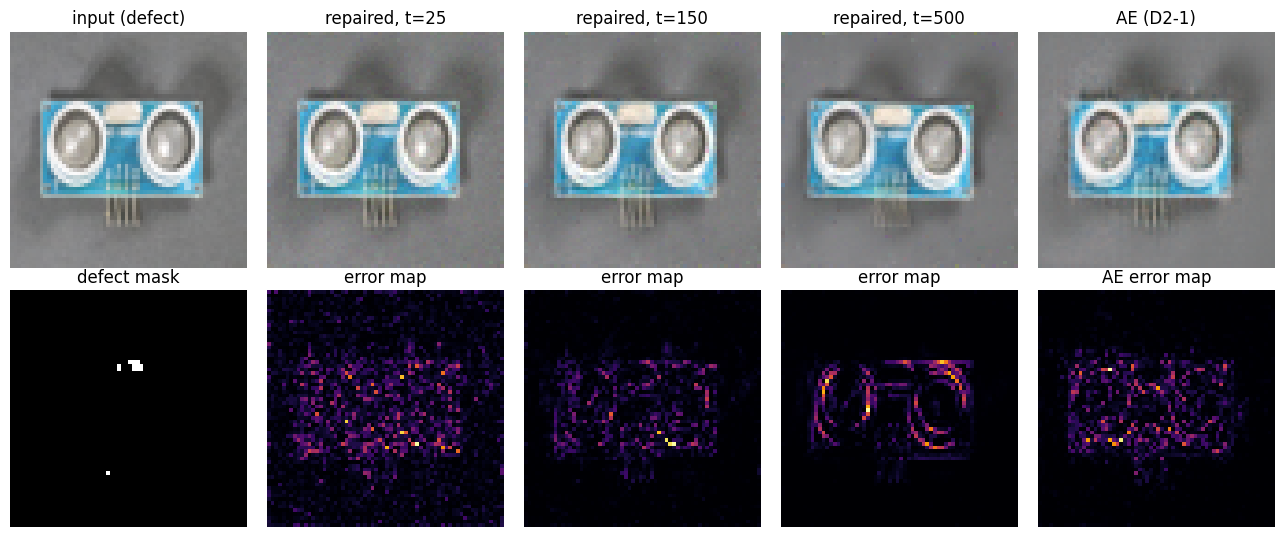

In [6]:
@torch.no_grad()
def diffusion_repair(x, t_start, steps=20, seed=SEED, batch=64):
    out = []
    g = torch.Generator(device=device).manual_seed(seed)
    ts = torch.linspace(t_start, 0, steps + 1).round().long().tolist()     # 例：200, 190, …, 0
    for xb in x.split(batch):
        x0 = xb.to(device) * 2 - 1
        x_t = sab[t_start] * x0 + s1mab[t_start] * torch.randn(x0.shape, device=device, generator=g)
        for t, t_prev in zip(ts[:-1], ts[1:]):
            eps_hat = net(x_t, torch.full((len(x_t),), t, device=device, dtype=torch.long))
            x0_hat = (x_t - s1mab[t] * eps_hat) / sab[t]                   # 目前估計的「乾淨版」（不要裁切：D3-3 的教訓）
            x_t = x0_hat if t_prev == 0 else sab[t_prev] * x0_hat + s1mab[t_prev] * eps_hat   # DDIM：放回 t_prev
        out.append(((x_t + 1) / 2).clamp(0, 1).cpu())
    return torch.cat(out)

# 一片不良品，在三個 t 的樣子
i_bad = int((data["val"]["y"] == 1).nonzero()[0])
xb = data["val"]["x"][i_bad:i_bad + 1]
T_SHOW = [25, 150, 500]
fig, ax = plt.subplots(2, len(T_SHOW) + 2, figsize=(13, 5.4))
ax[0, 0].imshow(xb[0].permute(1, 2, 0)); ax[0, 0].set_title("input (defect)")
ax[1, 0].imshow(data["val"]["m"][i_bad], cmap="gray"); ax[1, 0].set_title("defect mask")
for c, t in enumerate(T_SHOW, start=1):
    r = diffusion_repair(xb, t)
    ax[0, c].imshow(r[0].permute(1, 2, 0)); ax[0, c].set_title(f"repaired, t={t}")
    ax[1, c].imshow(((xb - r) ** 2).mean(1)[0], cmap="inferno"); ax[1, c].set_title("error map")
r_ae = ae_repair(xb)
ax[0, -1].imshow(r_ae[0].permute(1, 2, 0)); ax[0, -1].set_title("AE (D2-1)")
ax[1, -1].imshow(((xb - r_ae) ** 2).mean(1)[0], cmap="inferno"); ax[1, -1].set_title("AE error map")
for a in ax.flat: a.axis("off")
plt.tight_layout(); plt.savefig("t_three.png", dpi=120); plt.show()

**練習（投影片「練習：t 該選多少？」）**：先在投影片寫下你猜的最佳 t，再執行下一格，在**驗證集**上掃一輪。

t= 25  驗證集 AUROC 0.845  每張 8.6 ms
t= 50  驗證集 AUROC 0.888  每張 8.5 ms
t=100  驗證集 AUROC 0.913  每張 8.5 ms
t=150  驗證集 AUROC 0.909  每張 8.5 ms
t=250  驗證集 AUROC 0.858  每張 8.5 ms
t=400  驗證集 AUROC 0.703  每張 8.6 ms
驗證集上最好的 t ＝ 100 ｜AE 驗證集 AUROC 0.912


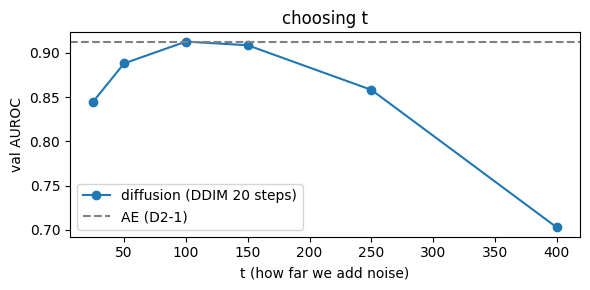

In [7]:
T_LIST = [25, 50, 100, 150, 250, 400]
sweep = {}
for t in T_LIST:
    _, _, s, ms = evaluate(lambda x: diffusion_repair(x, t, steps=20), data["val"]["x"])
    sweep[t] = (roc_auc_score(data["val"]["y"], s), ms)
    print(f"t={t:3d}  驗證集 AUROC {sweep[t][0]:.3f}  每張 {ms:.1f} ms")
BEST_T = max(sweep, key=lambda t: sweep[t][0])
RESULTS["t_sweep"] = {t: round(a, 3) for t, (a, _) in sweep.items()}
RESULTS["best_t"] = BEST_T
print("驗證集上最好的 t ＝", BEST_T, "｜AE 驗證集 AUROC", RESULTS["ae_val_auroc"])

plt.figure(figsize=(6, 3))
plt.plot(T_LIST, [sweep[t][0] for t in T_LIST], "o-", label="diffusion (DDIM 20 steps)")
plt.axhline(RESULTS["ae_val_auroc"], color="gray", ls="--", label="AE (D2-1)")
plt.xlabel("t (how far we add noise)"); plt.ylabel("val AUROC"); plt.legend(); plt.title("choosing t")
plt.tight_layout(); plt.savefig("t_sweep.png", dpi=120); plt.show()

## 5. DDIM：少走幾步，快多少？準度掉多少？
在最好的 t，比較「每一步都走」（t 步）和 DDIM 20、10、5 步。每張的毫秒數用 64 張一批量。

In [8]:
STEP_LIST = sorted({BEST_T, 20, 10, 5}, reverse=True)
step_res = {}
for k in STEP_LIST:
    _, _, s, ms = evaluate(lambda x: diffusion_repair(x, BEST_T, steps=k), data["val"]["x"])
    step_res[k] = (roc_auc_score(data["val"]["y"], s), ms)
    print(f"{k:4d} 步  驗證集 AUROC {step_res[k][0]:.3f}  每張 {ms:6.1f} ms  → 每秒 {1000/ms:6.1f} 張")
best_auc = max(a for a, _ in step_res.values())
BEST_STEPS = min(k for k, (a, _) in step_res.items() if a >= best_auc - 0.01)   # 準度掉不到 0.01 的最少步數
RESULTS["step_sweep"] = {k: [round(a, 3), round(ms, 2)] for k, (a, ms) in step_res.items()}
RESULTS["best_steps"] = BEST_STEPS
print("選定：t ＝", BEST_T, "、DDIM", BEST_STEPS, "步")

 100 步  驗證集 AUROC 0.908  每張   42.5 ms  → 每秒   23.5 張
  20 步  驗證集 AUROC 0.913  每張    8.5 ms  → 每秒  117.1 張
  10 步  驗證集 AUROC 0.917  每張    4.3 ms  → 每秒  233.8 張
   5 步  驗證集 AUROC 0.926  每張    2.1 ms  → 每秒  468.1 張
選定：t ＝ 100 、DDIM 5 步


## 6. 測試集：AE vs 擴散
**門檻**：和 D2-1 一樣，在**驗證集**上選「漏檢 ≤ 5%」的門檻，再到測試集算一次過殺與漏檢。

In [9]:
def threshold_for_miss(s, y, miss=0.05):
    bad = np.sort(s[y == 1].numpy())
    return float(bad[int(np.floor(miss * len(bad)))]) - 1e-12      # 至少 95% 的不良品分數 ≥ 門檻

def report(name, repair_fn):
    _, _, s_val, _ = evaluate(repair_fn, data["val"]["x"])
    thr = threshold_for_miss(s_val, data["val"]["y"])
    r, emap, s, ms = evaluate(repair_fn, data["test"]["x"])
    y = data["test"]["y"]
    over = (s[y == 0] > thr).float().mean().item()
    miss = (s[y == 1] <= thr).float().mean().item()
    auroc = roc_auc_score(y, s)
    row = dict(name=name, auroc=round(auroc, 3), over=round(over, 3), miss=round(miss, 3), ms=round(ms, 2),
               per_s=round(1000 / ms, 1), takt_ok=bool(ms / 1000 <= TAKT_S))
    print(f"{name:26s} AUROC {auroc:.3f} | 過殺 {over:6.1%} | 漏檢 {miss:6.1%} | 每張 {ms:7.2f} ms | 每秒 {1000/ms:7.1f} 張 | 趕得上節拍 {row['takt_ok']}")
    return row, r, emap

if device == "cuda": torch.cuda.reset_peak_memory_stats()
rows, recon = [], {}
for name, fn in [("AE（D2-1）", ae_repair),
                 (f"擴散 t={BEST_T}，每步都走", lambda x: diffusion_repair(x, BEST_T, steps=BEST_T)),
                 (f"擴散 t={BEST_T}，DDIM {BEST_STEPS} 步", lambda x: diffusion_repair(x, BEST_T, steps=BEST_STEPS))]:
    row, r, emap = report(name, fn); rows.append(row); recon[name] = (r, emap)
RESULTS["test_table"] = rows
if device == "cuda":
    RESULTS["eval_vram_gb"] = round(torch.cuda.max_memory_allocated() / 1e9, 2)
    print(f"VRAM 峰值 {RESULTS['eval_vram_gb']} GB")

AE（D2-1）                   AUROC 0.944 | 過殺  16.6% | 漏檢   6.0% | 每張    0.16 ms | 每秒  6072.4 張 | 趕得上節拍 True
擴散 t=100，每步都走              AUROC 0.922 | 過殺  43.0% | 漏檢   6.0% | 每張   42.86 ms | 每秒    23.3 張 | 趕得上節拍 True
擴散 t=100，DDIM 5 步          AUROC 0.930 | 過殺  36.4% | 漏檢   6.0% | 每張    2.14 ms | 每秒   467.8 張 | 趕得上節拍 True
VRAM 峰值 0.4 GB


**給作業員看的畫面**：原圖、擴散「修好」的版本、誤差圖、真正的瑕疵遮罩；最下面一列是 AE 的誤差圖。

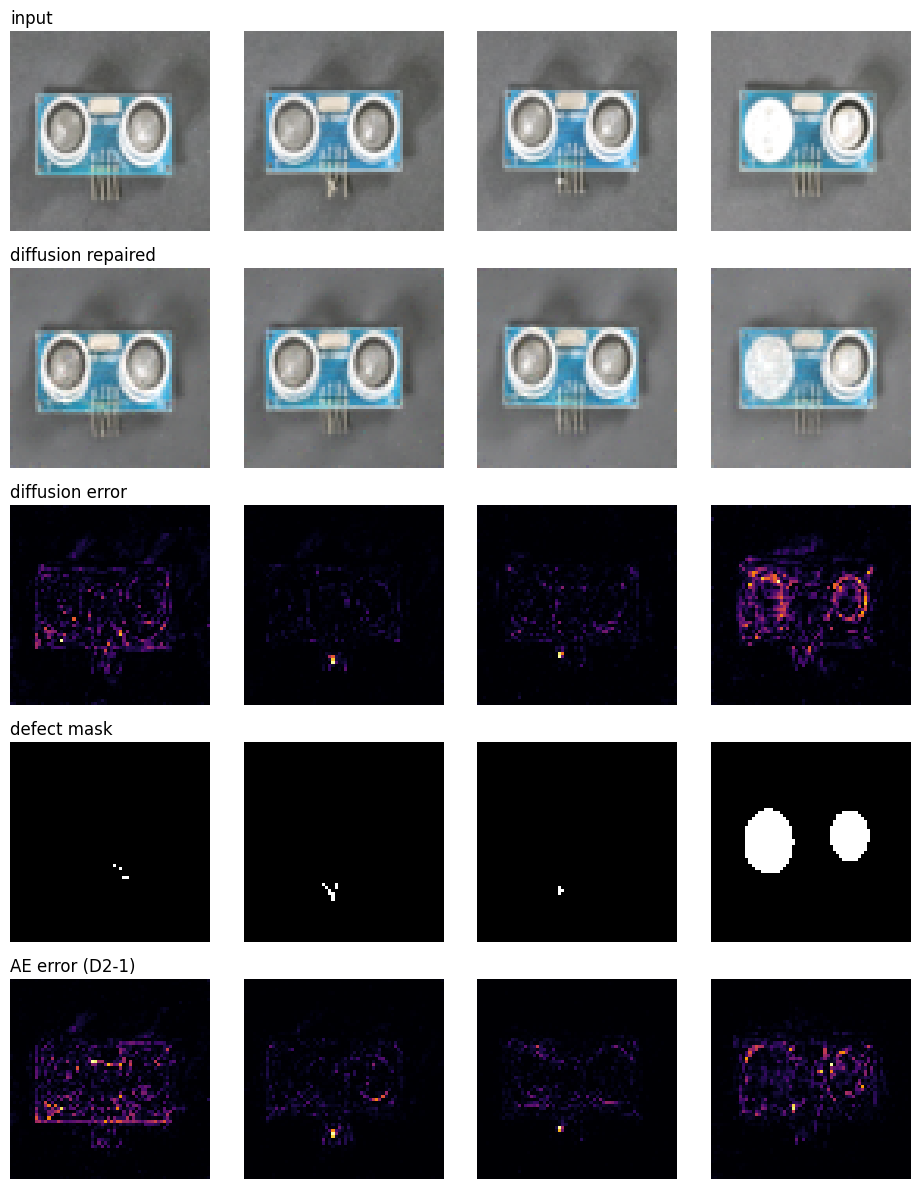

In [10]:
names = list(recon)
idx = (data["test"]["y"] == 1).nonzero()[:, 0][:4].tolist()
fig, ax = plt.subplots(5, 4, figsize=(9.5, 12))
for c, i in enumerate(idx):
    panels = [(data["test"]["x"][i].permute(1, 2, 0), None, "input"),
              (recon[names[2]][0][i].permute(1, 2, 0), None, "diffusion repaired"),
              (recon[names[2]][1][i], "inferno", "diffusion error"),
              (data["test"]["m"][i], "gray", "defect mask"),
              (recon[names[0]][1][i], "inferno", "AE error (D2-1)")]
    for r, (img, cmap, title) in enumerate(panels):
        ax[r, c].imshow(img, cmap=cmap); ax[r, c].axis("off")
        if c == 0: ax[r, c].set_title(title, loc="left")
plt.tight_layout(); plt.savefig("repair_examples.png", dpi=120); plt.show()

## 存檔
`results.json` 和所有圖打包成 `lab12_outputs.zip`（在 Colab 會自動下載）。

In [11]:
import zipfile
if device == "cuda": RESULTS["gpu"] = torch.cuda.get_device_name(0)
RESULTS.update(torch=torch.__version__, python=platform.python_version(), seed=SEED, size=SIZE, takt_s=TAKT_S, eval_n=EVAL_N)
json.dump(RESULTS, open("results.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print(json.dumps(RESULTS, ensure_ascii=False))
with zipfile.ZipFile("lab12_outputs.zip", "w") as z:
    for f in sorted(os.listdir(".")):
        if f.endswith((".png", ".json")) or (f == CKPT and TRAIN_DDPM): z.write(f)
try:
    from google.colab import files
    files.download("lab12_outputs.zip")
except ImportError:
    print("不在 Colab：lab12_outputs.zip 已存在目前資料夾")

{"ae_train_seconds": 11, "ae_val_auroc": 0.912, "ddpm_train_seconds": 439, "ddpm_train_vram_gb": 0.59, "ddpm_source": "trained here", "t_sweep": {"25": 0.845, "50": 0.888, "100": 0.913, "150": 0.909, "250": 0.858, "400": 0.703}, "best_t": 100, "step_sweep": {"100": [0.908, 42.53], "20": [0.913, 8.54], "10": [0.917, 4.28], "5": [0.926, 2.14]}, "best_steps": 5, "test_table": [{"name": "AE（D2-1）", "auroc": 0.944, "over": 0.166, "miss": 0.06, "ms": 0.16, "per_s": 6072.4, "takt_ok": true}, {"name": "擴散 t=100，每步都走", "auroc": 0.922, "over": 0.43, "miss": 0.06, "ms": 42.86, "per_s": 23.3, "takt_ok": true}, {"name": "擴散 t=100，DDIM 5 步", "auroc": 0.93, "over": 0.364, "miss": 0.06, "ms": 2.14, "per_s": 467.8, "takt_ok": true}], "eval_vram_gb": 0.4, "gpu": "Tesla T4", "torch": "2.14.1+cu130", "python": "3.13.16", "seed": 0, "size": 64, "takt_s": 1.0, "eval_n": null}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>